# Program Training - Jaringan Saraf Tiruan Back Propagation

Tugas Algoritma Kecerdasan Buatan. Jaringan multilayer (1 hidden layer) dilatih dengan algoritma *standard backpropagation* (Fausett, *Fundamentals of Neural Networks*, Bab 6, Bagian 6.1.2, hlm. 294-296) untuk mengenali **3 kelas** pakaian dan barang: T-shirt, Pants (celana), dan Shoes (sepatu), dari foto asli (dataset clothing-dataset-small). Foto berwarna dan berukuran beragam, sehingga ada tahap *preprocessing* (pemisahan objek dari latar dengan GrabCut, lalu ubah ukuran ke 100 x 100) sebelum masuk ke jaringan.

| Simbol di buku | Arti | Nama variabel |
|---|---|---|
| x_i | nilai input (piksel siluet objek / 255) | `x` |
| t_k | target output | `t` |
| z_in_j, z_j | masukan bersih dan keluaran node hidden | `z_in`, `z` |
| y_in_k, y_k | masukan bersih dan keluaran node output | `y_in`, `y` |
| v_ij, v_0j | bobot input-hidden dan bias hidden | `v`, `v_0` |
| w_jk, w_0k | bobot hidden-output dan bias output | `w`, `w_0` |
| delta_k, delta_in_j, delta_j | faktor galat | `delta_k`, `delta_in_j`, `delta_j` |
| delta w_jk, delta w_0k | selisih koreksi bobot W dan bias | `delta_w`, `delta_w_0` |
| delta v_ij, delta v_0j | selisih koreksi bobot V dan bias | `delta_v`, `delta_v_0` |
| alpha | learning rate | `alpha` |
| f(x), f'(x) | sigmoid biner dan turunannya | `f`, `f_aksen` |
| n, p, m | jumlah node input, hidden, output | `n`, `p`, `m` |

**Cara pakai di laptop:** letakkan `training.ipynb` di folder pendekatannya (folder `dataset/` boleh berada di folder yang sama atau satu tingkat di atasnya, seperti struktur repositori ini), lalu jalankan semua sel dari atas ke bawah (butuh `numpy`, `Pillow`, `matplotlib`, dan `opencv-python`; instal dengan `pip install numpy pillow matplotlib opencv-python`). File `bobot.npz` (berisi V, v_0, W, w_0) tersimpan di folder yang sama untuk dipakai di notebook pengujian.

**Cara pakai di Google Colab:** jalankan sel dari atas ke bawah. Saat diminta, unggah `dataset.zip`. Di akhir, `bobot.npz` otomatis diunduh.

In [1]:
import os
import zipfile
import numpy as np
import cv2
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

try:
    from google.colab import files
    DI_COLAB = True
except ImportError:      # dijalankan di komputer sendiri
    DI_COLAB = False

# Dataset: di Colab diunggah sebagai dataset.zip, di komputer sendiri cukup folder dataset/ di samping notebook
if DI_COLAB and not os.path.isdir("dataset"):
    print("Unggah dataset.zip")
    unggah = files.upload()
    with zipfile.ZipFile(list(unggah.keys())[0]) as zf:
        zf.extractall(".")
DIR_DATASET = "dataset" if os.path.isdir("dataset") else os.path.join("..", "dataset")   # di samping notebook (Colab) atau satu tingkat di atas (struktur repositori)
print("Folder dataset:", sorted(os.listdir(DIR_DATASET)))

Folder dataset: ['kelas1_tshirt', 'kelas2_pants', 'kelas3_shoes', 'sumber_gambar.csv']


## Parameter jaringan

* Setelah preprocessing, semua gambar berukuran **100 x 100 piksel**, sehingga jumlah node input `n` = 10.000.
* Node hidden `p` = 100 (bebas). Node output `m` = **3** (pola target 1 0 0, 0 1 0, dan 0 0 1).
* Hlm. 300 buku memakai total squared error < 0,05 sebagai syarat berhenti pada contoh XOR; nilai yang sama dipakai di sini.
* Pada data siluet, galat berhenti turun di sekitar 1 (satu foto latih, `kelas2_pants/img27.jpg`, berupa celana tergeletak diagonal di atas karpet bermotif, siluetnya tidak mirip celana lain sehingga tidak terpisahkan) dan tidak akan mencapai 0,05, sedangkan akurasi pada data yang tidak ikut dilatih sudah stabil sejak sekitar epoch ke-25. Karena itu batas **100 epoch** dipakai (buku hlm. 298: melatih sampai galat minimum tidak selalu menguntungkan).

In [2]:
UKURAN = (100, 100)                  # tinggi x lebar; semua gambar disamakan ke ukuran ini
n = UKURAN[0] * UKURAN[1]            # jumlah node input X (= jumlah piksel)
p = 100                              # jumlah node hidden Z
m = 3                                # jumlah node output Y (tepat 3)
alpha = 0.05                         # learning rate
galat_maks = 0.05                    # syarat berhenti: total squared error < galat_maks
epoch_maks = 100                     # atau jumlah epoch maksimum tercapai

KELAS = ["kelas1_tshirt", "kelas2_pants", "kelas3_shoes"]
NAMA_KELAS = ["T-shirt", "Pants (celana)", "Shoes (sepatu)"]
JUMLAH_LATIH = 50                    # img01..img50 dipakai melatih, img51..img65 disimpan untuk uji

## Membaca dataset

Foto asli berwarna (RGB), berukuran sekitar 400 x 533 piksel, dengan latar yang beragam (lantai, karpet, kain). Tahap *preprocessing* untuk setiap gambar:

1. putar sesuai orientasi kamera (EXIF) bila perlu,
2. **pisahkan objek dari latar** dengan GrabCut (OpenCV; bingkai awal 92% bagian tengah gambar),
3. ubah hasilnya menjadi **siluet**: objek = putih (255), latar = hitam (0), disimpan sebagai citra 8-bit satu kanal,
4. ubah ukuran ke **100 x 100** piksel,
5. ratakan menjadi vektor `x` berukuran `n` = 10.000,
6. normalkan ke rentang 0 sampai 1 (bagi 255).

Alasan: pada percobaan dengan 201 foto yang tidak ikut dilatih, preprocessing grayscale biasa menghasilkan akurasi 68,2% (jaringan banyak "belajar" dari latar), sedangkan siluet hasil GrabCut menghasilkan sekitar 81%. Catatan: ketentuan dosen meminta citra diubah ke grayscale; pada langkah ini citra dikonversi menjadi citra 8-bit satu kanal (hanya bernilai 0 atau 255), sehingga informasi warna dan tekstur kain tidak dipakai, hanya bentuk objek. Versi grayscale biasa tersedia di folder `with_grayscale/`.

Langkah yang persis sama dipakai di notebook pengujian. Target `t` untuk kelas 1, 2, dan 3 berturut-turut adalah `1 0 0`, `0 1 0`, dan `0 0 1`.

Data latih : (150, 10000)  target: (150, 3)
Data uji   : (45, 10000) (tidak ikut dilatih)


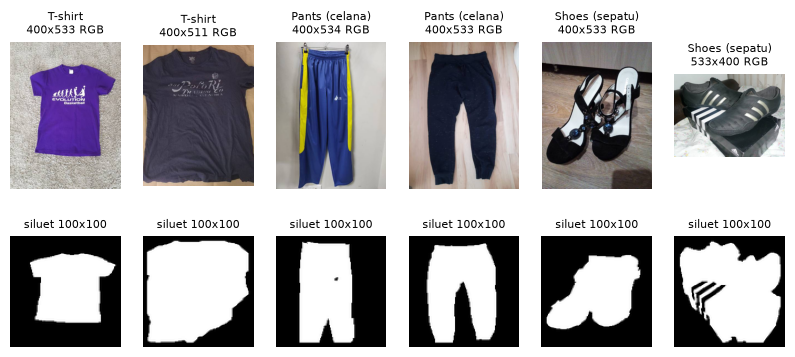

In [3]:
# --- Preprocessing: pisahkan objek dari latar (GrabCut, OpenCV), lalu siluet 100 x 100 ---
def siluet_objek(gambar):
    # Segmentasi GrabCut dengan bingkai awal 92% bagian tengah gambar (objek diasumsikan di dalam bingkai).
    rgb = np.asarray(gambar.convert("RGB"))
    tinggi, lebar = rgb.shape[:2]
    skala = 200 / max(tinggi, lebar)                                    # GrabCut dijalankan pada gambar kecil
    kecil = cv2.resize(rgb, (int(lebar * skala), int(tinggi * skala)), interpolation=cv2.INTER_AREA)
    bgr = kecil[:, :, ::-1].copy()
    h, w = bgr.shape[:2]
    bingkai = (int(w * 0.04), int(h * 0.04), int(w * 0.92), int(h * 0.92))
    topeng = np.zeros((h, w), np.uint8)
    model_latar, model_objek = np.zeros((1, 65)), np.zeros((1, 65))
    cv2.setRNGSeed(0)                                                   # hasil sama pada setiap pemanggilan
    cv2.grabCut(bgr, topeng, bingkai, model_latar, model_objek, 5, cv2.GC_INIT_WITH_RECT)
    return (topeng == cv2.GC_FGD) | (topeng == cv2.GC_PR_FGD)           # True = objek, False = latar

def praproses(gambar):
    objek = siluet_objek(gambar)                                        # 1. pisahkan objek dari latar
    siluet = Image.fromarray((objek * 255).astype(np.uint8))            # 2. siluet: objek = 255, latar = 0 (citra 8-bit)
    siluet = siluet.resize((UKURAN[1], UKURAN[0]), Image.LANCZOS)       # 3. samakan ukuran ke 100 x 100
    x = np.asarray(siluet, dtype=np.float64).flatten() / 255.0          # 4. ratakan + 5. normalisasi 0..1
    assert x.shape == (n,)
    return x, siluet, objek.mean()


def baca_gambar(path):
    gambar = ImageOps.exif_transpose(Image.open(path))              # putar sesuai orientasi kamera
    return praproses(gambar)[0]

X_latih, T_latih, X_uji, T_uji, nama_uji = [], [], [], [], []
for k, kelas in enumerate(KELAS):
    t = np.zeros(m)
    t[k] = 1.0                                                   # pola target 1 0 0 / 0 1 0 / 0 0 1
    berkas = sorted(b for b in os.listdir(os.path.join(DIR_DATASET, kelas)) if b.lower().endswith(".jpg"))
    assert len(berkas) >= 15, f"{kelas}: minimal 15 gambar"
    for urut, nama in enumerate(berkas):
        x = baca_gambar(os.path.join(DIR_DATASET, kelas, nama))
        if urut < JUMLAH_LATIH:
            X_latih.append(x); T_latih.append(t)
        else:
            X_uji.append(x); T_uji.append(t); nama_uji.append(f"{kelas}/{nama}")

X_latih, T_latih = np.array(X_latih), np.array(T_latih)
X_uji, T_uji = np.array(X_uji), np.array(T_uji)
print("Data latih :", X_latih.shape, " target:", T_latih.shape)
print("Data uji   :", X_uji.shape, "(tidak ikut dilatih)")

# Contoh sebelum (foto asli) dan sesudah preprocessing (siluet 100 x 100)
fig, sumbu = plt.subplots(2, 6, figsize=(10, 4.2))
for k in range(3):
    for c in range(2):
        nama = sorted(b for b in os.listdir(os.path.join(DIR_DATASET, KELAS[k])) if b.lower().endswith(".jpg"))[c]
        asli = ImageOps.exif_transpose(Image.open(os.path.join(DIR_DATASET, KELAS[k], nama)))
        sumbu[0, k * 2 + c].imshow(asli); sumbu[0, k * 2 + c].axis("off")
        sumbu[0, k * 2 + c].set_title(f"{NAMA_KELAS[k]}\n{asli.size[0]}x{asli.size[1]} RGB", fontsize=8)
        sumbu[1, k * 2 + c].imshow(X_latih[k * JUMLAH_LATIH + c].reshape(UKURAN), cmap="gray"); sumbu[1, k * 2 + c].axis("off")
        sumbu[1, k * 2 + c].set_title("siluet 100x100", fontsize=8)
plt.show()

## Fungsi aktivasi (hlm. 293)

Sigmoid biner: $f(x) = \frac{1}{1+e^{-x}}$ dengan turunan $f'(x) = f(x)\,[1-f(x)]$.

In [4]:
def f(x):
    return 1.0 / (1.0 + np.exp(-x))

def f_aksen(x):
    return f(x) * (1.0 - f(x))

## Langkah 0 - Inisialisasi bobot

Bobot awal W dan bias w_0 berupa bilangan acak antara -0,5 dan 0,5. Bobot V diinisialisasi dengan cara **Nguyen-Widrow** (hlm. 297-298) agar node hidden tidak langsung jenuh (daerah sigmoid dengan turunan sangat kecil):

* $\beta = 0{,}7\,p^{1/n}$
* $v_{ij}$ awal acak antara -0,5 dan 0,5, lalu $v_{ij} = \beta\,v_{ij}(\text{lama}) / \lVert v_j(\text{lama})\rVert$
* $v_{0j}$ acak antara $-\beta$ dan $\beta$

In [5]:
rng = np.random.default_rng(1)

beta = 0.7 * p ** (1.0 / n)
v = rng.uniform(-0.5, 0.5, (n, p))             # v[i, j] = v_ij
v = beta * v / np.linalg.norm(v, axis=0)       # normalisasi tiap kolom v_j (Nguyen-Widrow)
v_0 = rng.uniform(-beta, beta, p)              # v_0[j] = v_0j
w = rng.uniform(-0.5, 0.5, (p, m))             # w[j, k] = w_jk
w_0 = rng.uniform(-0.5, 0.5, m)                # w_0[k] = w_0k
print(f"n={n}, p={p}, m={m}, beta={beta:.4f}, alpha={alpha}")

n=10000, p=100, m=3, beta=0.7003, alpha=0.05


## Langkah 1 sampai 9 - Pelatihan

Setiap epoch memproses seluruh pasangan data latih satu per satu (pembaruan bobot per pola, hlm. 296). Urutan pola diacak pada tiap epoch agar kelas tidak terurut. Galat yang dicetak adalah total squared error: jumlah $(t_k - y_k)^2$ untuk semua node output dan semua pola latih pada epoch itu.

In [6]:
riwayat_galat = []
epoch = 0
berhenti = False

while not berhenti and epoch < epoch_maks:                  # Langkah 1
    epoch += 1
    galat = 0.0
    for q in rng.permutation(len(X_latih)):                  # Langkah 2: untuk setiap pasangan (x, t)
        x, t = X_latih[q], T_latih[q]

        # Langkah 3: node input X_i menerima x_i dan meneruskannya ke node hidden
        # Langkah 4: node hidden Z_j
        z_in = v_0 + x @ v                                   # z_in_j = v_0j + sum_i x_i v_ij
        z = f(z_in)                                          # z_j = f(z_in_j)

        # Langkah 5: node output Y_k
        y_in = w_0 + z @ w                                   # y_in_k = w_0k + sum_j z_j w_jk
        y = f(y_in)                                          # y_k = f(y_in_k)

        # Langkah 6: galat di node output
        delta_k = (t - y) * f_aksen(y_in)                    # delta_k = (t_k - y_k) f'(y_in_k)
        delta_w = alpha * np.outer(z, delta_k)               # delta w_jk = alpha delta_k z_j
        delta_w_0 = alpha * delta_k                          # delta w_0k = alpha delta_k

        # Langkah 7: galat di node hidden (memakai w yang lama)
        delta_in_j = w @ delta_k                             # delta_in_j = sum_k delta_k w_jk
        delta_j = delta_in_j * f_aksen(z_in)                 # delta_j = delta_in_j f'(z_in_j)
        delta_v = alpha * np.outer(x, delta_j)               # delta v_ij = alpha delta_j x_i
        delta_v_0 = alpha * delta_j                          # delta v_0j = alpha delta_j

        # Langkah 8: perbarui bobot dan bias
        w = w + delta_w
        w_0 = w_0 + delta_w_0
        v = v + delta_v
        v_0 = v_0 + delta_v_0

        galat += np.sum((t - y) ** 2)

    riwayat_galat.append(galat)
    print(f"Epoch ke-{epoch:3d} | total squared error = {galat:.4f}")
    berhenti = galat < galat_maks                            # Langkah 9: uji syarat berhenti

print()
print(f"Pelatihan berhenti pada epoch ke-{epoch}, total squared error = {riwayat_galat[-1]:.4f}")

Epoch ke-  1 | total squared error = 117.1383
Epoch ke-  2 | total squared error = 87.0881
Epoch ke-  3 | total squared error = 83.4528
Epoch ke-  4 | total squared error = 53.5916
Epoch ke-  5 | total squared error = 42.6705
Epoch ke-  6 | total squared error = 30.8981
Epoch ke-  7 | total squared error = 27.9234
Epoch ke-  8 | total squared error = 24.8674
Epoch ke-  9 | total squared error = 19.2484
Epoch ke- 10 | total squared error = 18.4917
Epoch ke- 11 | total squared error = 17.0134
Epoch ke- 12 | total squared error = 11.4486
Epoch ke- 13 | total squared error = 11.1051
Epoch ke- 14 | total squared error = 9.0228
Epoch ke- 15 | total squared error = 5.8039
Epoch ke- 16 | total squared error = 5.6688
Epoch ke- 17 | total squared error = 4.1266
Epoch ke- 18 | total squared error = 2.9619
Epoch ke- 19 | total squared error = 2.6627
Epoch ke- 20 | total squared error = 2.1994
Epoch ke- 21 | total squared error = 2.1196
Epoch ke- 22 | total squared error = 2.0135
Epoch ke- 23 | tot

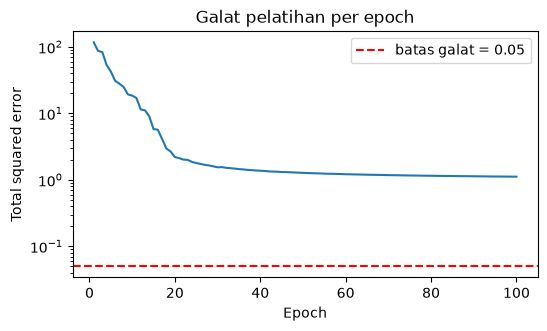

In [7]:
plt.figure(figsize=(6, 3.2))
plt.plot(range(1, len(riwayat_galat) + 1), riwayat_galat)
plt.axhline(galat_maks, color="r", linestyle="--", label=f"batas galat = {galat_maks}")
plt.xlabel("Epoch"); plt.ylabel("Total squared error"); plt.yscale("log")
plt.title("Galat pelatihan per epoch"); plt.legend(); plt.show()

## Pemeriksaan pada data yang tidak ikut dilatih

Hanya umpan maju (*application procedure*, hlm. 299-300): kelas diambil dari node output dengan nilai terbesar.

In [8]:
def maju(x):
    z = f(v_0 + x @ v)
    return f(w_0 + z @ w)

def akurasi(X, T):
    Y = np.array([maju(x) for x in X])
    return np.mean(Y.argmax(axis=1) == T.argmax(axis=1)), Y

acc_latih, _ = akurasi(X_latih, T_latih)
acc_uji, Y_uji = akurasi(X_uji, T_uji)
print(f"Akurasi data latih : {acc_latih * 100:.1f}%")
print(f"Akurasi data uji   : {acc_uji * 100:.1f}%  ({len(X_uji)} gambar yang tidak ikut dilatih)\n")
print(f"{'Gambar uji':<28} {'Y1':>6} {'Y2':>6} {'Y3':>6}  Hasil")
for nama, y, t in zip(nama_uji, Y_uji, T_uji):
    print(f"{nama:<28} {y[0]:6.3f} {y[1]:6.3f} {y[2]:6.3f}  {NAMA_KELAS[y.argmax()]} {'(benar)' if y.argmax() == t.argmax() else '(SALAH)'}")

Akurasi data latih : 99.3%
Akurasi data uji   : 80.0%  (45 gambar yang tidak ikut dilatih)

Gambar uji                       Y1     Y2     Y3  Hasil
kelas1_tshirt/img51.jpg       0.992  0.014  0.004  T-shirt (benar)
kelas1_tshirt/img52.jpg       0.985  0.003  0.017  T-shirt (benar)
kelas1_tshirt/img53.jpg       0.994  0.000  0.007  T-shirt (benar)
kelas1_tshirt/img54.jpg       0.979  0.026  0.006  T-shirt (benar)
kelas1_tshirt/img55.jpg       0.992  0.004  0.005  T-shirt (benar)
kelas1_tshirt/img56.jpg       0.769  0.301  0.003  T-shirt (benar)
kelas1_tshirt/img57.jpg       0.985  0.001  0.025  T-shirt (benar)
kelas1_tshirt/img58.jpg       0.997  0.003  0.003  T-shirt (benar)
kelas1_tshirt/img59.jpg       0.116  0.077  0.627  Shoes (sepatu) (SALAH)
kelas1_tshirt/img60.jpg       0.995  0.004  0.005  T-shirt (benar)
kelas1_tshirt/img61.jpg       0.997  0.005  0.002  T-shirt (benar)
kelas1_tshirt/img62.jpg       0.996  0.009  0.002  T-shirt (benar)
kelas1_tshirt/img63.jpg       0.984  0.0

## Menyimpan bobot

Hasil pelatihan (V, v_0, W, w_0) disimpan dalam **satu file** `bobot.npz`.

In [9]:
np.savez("bobot.npz", v=v, v_0=v_0, w=w, w_0=w_0,
         ukuran=np.array(UKURAN), nama_kelas=np.array(NAMA_KELAS))
print("Tersimpan: bobot.npz ->", {k: np.load("bobot.npz")[k].shape for k in ["v", "v_0", "w", "w_0"]})
if DI_COLAB:
    files.download("bobot.npz")

Tersimpan: bobot.npz -> {'v': (10000, 100), 'v_0': (100,), 'w': (100, 3), 'w_0': (3,)}


## Sumber dataset

Gambar pada folder `dataset/` berasal dari **clothing-dataset-small** (Alexey Grigorev), bukan dikumpulkan sendiri.

* **Repositori:** https://github.com/alexeygrigorev/clothing-dataset-small
* **Lisensi:** Creative Commons Zero v1.0 (CC0 1.0). README repositori: "This dataset can be freely used for any purpose."
* **Yang dipakai:** foto berwarna (JPEG, sekitar 400 x 533 piksel) dari tiga dari sepuluh kelas: `t-shirt`, `pants`, dan `shoes`. Tiap kelas 65 foto: 50 diambil acak dari folder `train` repositori (25 dengan `random.seed(2026)` dan 25 tambahan dengan `random.seed(2027)`) dan 15 dari folder `test`. Foto tidak diubah; `img01`-`img50` dipakai melatih dan `img51`-`img65` untuk uji. Pemetaan nama berkas ke berkas asli ada di `dataset/sumber_gambar.csv`.
* **Preprocessing** (pemisahan objek dengan GrabCut dan ubah ukuran ke 100 x 100) dilakukan oleh program, bukan pada berkas dataset.